# 04: Models and real-time backtest

Can small models using monthly indicators nowcast India's GDP first print better than simply repeating last quarter's print? This notebook runs each model in real time at three nowcast dates and compares it with that naive rule.

**Setup**

- **Target:** `gdp_growth_first_print`, 2017Q2 to 2025Q3, all on the 2011-12 base.
- **Nowcast dates:** D+0, D+32 and D+45 days after quarter-end, from notebook 03.
- **Real-time rule:** a monthly value is used only if its `release_date` is on or before the nowcast date. A GDP first print is used only if released before it. Undated first-print values are never used.
- **Partial quarters:** YoY uses the months available, compared with the same months a year earlier (first print against first print, as in notebook 03).
- **COVID quarters:** 2020Q2 to 2022Q2. Headline metrics use only non-COVID test quarters, and COVID test quarters are reported separately.
- **Look-ahead series:** e-way bills and diesel are latest vintage with no release dates. They are labelled `[look-ahead]` everywhere and appear only as a sensitivity.


## Why there is no XGBoost or dynamic factor model

There are 28 core 8 quarters, 19 of them outside COVID, and the backtest starts with 8 training quarters.

- **XGBoost** learns splits and interactions from the data. With 8 to 30 rows it would mostly fit noise, and early-stopping or tuning would need a validation set this sample doesn't have.
- **A dynamic factor model** estimates loadings, factor dynamics and error variances from many series. Here there are 2 to 3 usable series, with gaps and a structural break (COVID), so the factor would essentially be core 8.

Both would also make it harder to see why a nowcast moved. The models below have 1 to 4 coefficients.

## Setup

In [1]:
import datetime as dt
import warnings
from functools import lru_cache
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300, "display.max_colwidth", 70)

PROCESSED, REPORTS = Path("../data/processed"), Path("../reports")
INK, MUTED, GRID = "#1F2933", "#616E7C", "#E4E7EB"
BLUE, ORANGE, TEAL = "#2a6fbb", "#d9731a", "#1b9e8a"
COVID_BAND = "#ECEDEF"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

WINDOW = [str(p) for p in pd.period_range("2017Q2", "2025Q3", freq="Q")]
NEW_BASE = ["2025Q4", "2026Q1", "2026Q2"]
COVID = {str(p) for p in pd.period_range("2020Q2", "2022Q2", freq="Q")}
DATES = {"D+0": 0, "D+32": 32, "D+45": 45}
VARIANTS = {"drop": "(a) COVID dropped from training", "dummy": "(b) COVID kept, with a dummy"}
MIN_TRAIN = 8

gdp_table = pd.read_csv(PROCESSED / "gdp.csv", parse_dates=["release_date"]).set_index("quarter")
prov = pd.read_csv(PROCESSED / "gdp_provenance.csv").set_index("quarter")
GDP, REL = gdp_table["gdp_growth_first_print"], gdp_table["release_date"]
assert (prov.loc[WINDOW, "base_year"] == "2011-12").all() and (prov.loc[NEW_BASE, "base_year"] == "2022-23").all()
UNVERIFIED = [q for q in prov.index[~prov["verified_release_day"]] if q in WINDOW]
print("Unverified release days inside the window:", UNVERIFIED)

def qend(q):
    return pd.Period(q, freq="Q").end_time.normalize()

def prevq(q):
    return str(pd.Period(q, freq="Q") - 1)

SOURCES = {  # key: (indicator, vintage, has release dates)
    "core8": ("core8_overall_base2011", "first", True),
    "iip": ("iip_general_base2011", "first", True),
    "exports": ("merch_exports", "first", True),
    "gst": ("gst_gross_collection", "first", True),
    "eway": ("eway_bills", "latest", False),
    "diesel": ("diesel_hsd_consumption", "latest", False),
}
monthly = pd.read_csv(PROCESSED / "indicators_monthly.csv", parse_dates=["release_date"])
VALUES = {}
for key, (name, vintage, dated) in SOURCES.items():
    x = monthly[(monthly.indicator == name) & (monthly.vintage == vintage) & monthly.value.notna()]
    VALUES[key] = pd.DataFrame({"value": x.value.values, "released": x.release_date.values}, index=pd.PeriodIndex(x.ref_month, freq="M"))
    if dated:
        print(f"{key:8s} {len(x)} first-print values, {x.release_date.isna().sum()} undated and therefore never used")

Unverified release days inside the window: ['2019Q3', '2021Q3']
core8    108 first-print values, 0 undated and therefore never used
iip      94 first-print values, 0 undated and therefore never used
exports  95 first-print values, 0 undated and therefore never used
gst      89 first-print values, 30 undated and therefore never used


## Real-time data access

`positions` finds which months of a quarter, 1 to 3, have both the current value and the value a year earlier public by the nowcast date. Training quarters use the same month positions as the quarter being nowcast, so the regression is fitted on the same kind of partial YoY it is applied to.

Look-ahead series have no release dates. **They are assumed to have the same months available as core 8 on that date**, which is an assumption, not data.

In [2]:
@lru_cache(maxsize=None)
def month_value(key, month, asof):
    t = VALUES[key]
    if month not in t.index:
        return None
    row = t.loc[month]
    if SOURCES[key][2] and not (row.released <= asof):  # NaT never counts as released
        return None
    return row.value

def quarter_months(q):
    p = pd.Period(q, freq="Q")
    return list(pd.period_range(p.start_time, periods=3, freq="M"))

@lru_cache(maxsize=None)
def positions(key, q, asof):
    found = tuple(i + 1 for i, m in enumerate(quarter_months(q)) if month_value(key, m, asof) is not None and month_value(key, m - 12, asof) is not None)
    if SOURCES[key][2]:
        return found
    return tuple(i for i in positions("core8", q, asof) if i in found)

@lru_cache(maxsize=None)
def yoy(key, q, pos, asof):
    months = [quarter_months(q)[i - 1] for i in pos]
    cur, base = [month_value(key, m, asof) for m in months], [month_value(key, m - 12, asof) for m in months]
    if not pos or None in cur or None in base:
        return np.nan
    return 100 * (sum(cur) / sum(base) - 1)  # equal month counts, so sum and mean give the same ratio

def gdp_known(q, asof):
    return GDP[q] if q in GDP.index and REL[q] < asof else np.nan

## Models

| # | Model | Regressors |
|---|---|---|
| 1 | Naive | Previous quarter's first print |
| 2 | AR(1) | Previous first print |
| 3 | Bridge | Core 8 partial-quarter YoY |
| 4 | Bridge + AR | Core 8 YoY, previous first print |
| 5 | Bridge, IIP | IIP partial-quarter YoY |
| 6a, 6b | Add-on tests | Core 8 YoY plus exports, or plus GST |
| 7a, 7b | Look-ahead sensitivity | Core 8 YoY plus e-way bills or diesel, `[look-ahead]` |

All except the naive model are OLS with an intercept, refitted for every quarter and nowcast date on all earlier quarters in the window whose first print was out by that date.

- **Variant (a)** drops COVID quarters from training. For AR terms it also drops 2022Q3, whose previous quarter is COVID.
- **Variant (b)** keeps them and adds a COVID dummy. The dummy is 1 when nowcasting a COVID quarter and 0 otherwise.
- **A nowcast needs at least 8 training quarters,** so the first test quarter is the first one that reaches 8.

**Model 8 (Phase 4b, pre-registered, the only model added after Phase 4):** a change model. It regresses the change in the GDP first print from the previous quarter's first print on the change in core 8 partial-quarter YoY from the quarter before, using the same month positions in both quarters and only data available on the nowcast date. The nowcast is the previous first print plus the predicted change. It uses the same variants, dummy and minimum of 8 training quarters. In variant (a), training also drops 2022Q3, whose previous quarter is COVID, as for the AR terms. It is scored on the same quarter sets as the Phase 4 main tables, and isn't eligible for the Phase 4 "best model" selection.

In [3]:
MODELS = {
    "1 Naive": None,
    "2 AR(1)": ["ar"],
    "3 Bridge: core 8": ["core8"],
    "4 Bridge + AR: core 8": ["core8", "ar"],
    "5 Bridge: IIP": ["iip"],
    "6a Bridge + exports": ["core8", "exports"],
    "6b Bridge + GST": ["core8", "gst"],
    "7a Bridge + e-way bills [look-ahead]": ["core8", "eway"],
    "7b Bridge + diesel [look-ahead]": ["core8", "diesel"],
    "8 Change: Δ core 8": "change",  # Phase 4b, pre-registered
}
MAIN = list(MODELS)[:5]
M8 = "8 Change: Δ core 8"

def regressors(feats, q, pos, asof):
    return [gdp_known(prevq(q), asof) if f == "ar" else yoy(f, q, pos[f], asof) for f in feats]

def fit_predict(feats, variant, t, asof, drop=(), train_quarters=WINDOW, x_override=None):
    pos = {f: positions(f, t, asof) for f in feats if f != "ar"}
    if any(len(p) == 0 for p in pos.values()):
        return None
    x_t = x_override if x_override is not None else regressors(feats, t, pos, asof)
    if np.isnan(x_t).any():
        return None
    X, y, dummy = [], [], []
    for j in train_quarters:
        if j >= t or not REL[j] < asof or j in drop:
            continue
        if variant == "drop" and (j in COVID or ("ar" in feats and prevq(j) in COVID)):
            continue
        x = regressors(feats, j, pos, asof)
        if np.isnan(x).any():
            continue
        X.append(x); y.append(GDP[j]); dummy.append(float(j in COVID))
    if len(y) < MIN_TRAIN:
        return None
    X = np.column_stack([np.ones(len(y)), np.array(X)])
    use_dummy = variant == "dummy" and any(dummy)
    if use_dummy:
        X = np.column_stack([X, dummy])
    beta = np.linalg.lstsq(X, np.array(y), rcond=None)[0]
    xt = np.r_[1.0, x_t, [float(t in COVID)] if use_dummy else []]
    return {"nowcast": float(xt @ beta), "n_train": len(y), "months": ",".join(f"{f}:{''.join(map(str, p))}" for f, p in pos.items())}

def fit_change(variant, t, asof, drop=()):
    """Model 8: ΔGDP first print on Δ core 8 partial-quarter YoY, same month positions in both quarters."""
    pos = positions("core8", t, asof)
    if not pos:
        return None
    dx = lambda q: yoy("core8", q, pos, asof) - yoy("core8", prevq(q), pos, asof)
    x_t, last = dx(t), gdp_known(prevq(t), asof)
    if np.isnan([x_t, last]).any():
        return None
    X, y, dummy = [], [], []
    for j in WINDOW:
        if j >= t or not REL[j] < asof or j in drop:
            continue
        if variant == "drop" and (j in COVID or prevq(j) in COVID):
            continue
        x = dx(j)
        if np.isnan(x) or prevq(j) not in GDP.index:
            continue
        X.append(x); y.append(GDP[j] - GDP[prevq(j)]); dummy.append(float(j in COVID))
    if len(y) < MIN_TRAIN:
        return None
    X = np.column_stack([np.ones(len(y)), X])
    use_dummy = variant == "dummy" and any(dummy)
    if use_dummy:
        X = np.column_stack([X, dummy])
    beta = np.linalg.lstsq(X, np.array(y), rcond=None)[0]
    xt = np.r_[1.0, x_t, [float(t in COVID)] if use_dummy else []]
    return {"nowcast": last + float(xt @ beta), "n_train": len(y), "months": "core8:" + "".join(map(str, pos))}

def run_backtest(drop=(), quarters=WINDOW + NEW_BASE):
    rows = []
    for t in quarters:
        if t in drop:
            continue
        for date, days in DATES.items():
            asof = qend(t) + pd.Timedelta(days=days)
            last = max(q for q in GDP.index if REL[q] < asof)
            naive = GDP[last]
            for model, feats in MODELS.items():
                for variant in VARIANTS:
                    if feats is None:
                        out = {"nowcast": naive, "n_train": np.nan, "months": ""}
                    elif feats == "change":
                        out = fit_change(variant, t, asof, drop)
                    else:
                        out = fit_predict(feats, variant, t, asof, drop)
                    if out is not None:
                        rows.append({"model": model, "variant": variant, "date": date, "quarter": t, "asof": asof, **out,
                                     "actual": GDP.get(t, np.nan), "naive": naive, "last_print": last,
                                     "days_before_gdp": (REL[t] - asof).days if t in REL.index else np.nan})
    return pd.DataFrame(rows)

nowcasts = run_backtest()
print("Previous quarter's print not yet out at a nowcast date:", int((nowcasts.last_print != nowcasts.quarter.map(prevq)).sum()), "cases")
nowcasts.to_csv(PROCESSED / "backtest_nowcasts.csv", index=False)
first_test = nowcasts[nowcasts.quarter.isin(WINDOW)].groupby(["model", "variant", "date"]).quarter.min().unstack("date")
display(first_test.loc[list(MODELS)[1:]])

Previous quarter's print not yet out at a nowcast date: 0 cases


date                                             D+0    D+32    D+45
model                                variant                        
2 AR(1)                              drop     2019Q2  2019Q2  2019Q2
                                     dummy    2019Q2  2019Q2  2019Q2
3 Bridge: core 8                     drop     2022Q4  2022Q4  2022Q4
                                     dummy    2020Q3  2020Q3  2020Q3
4 Bridge + AR: core 8                drop     2023Q1  2023Q1  2023Q1
                                     dummy    2020Q3  2020Q3  2020Q3
5 Bridge: IIP                        drop     2022Q4  2023Q2  2024Q2
                                     dummy    2020Q4  2020Q4  2022Q1
6a Bridge + exports                  drop     2024Q2  2024Q2  2024Q2
                                     dummy    2021Q4  2021Q4  2021Q4
6b Bridge + GST                      dummy    2022Q2  2022Q1  2022Q1
7a Bridge + e-way bills [look-ahead] drop     2023Q4  2023Q4  2023Q4
                                     dummy    2021Q3  2021Q3  2021Q3
7b Bridge + diesel [look-ahead]      drop     2024Q3  2024Q3  2024Q3
                                     dummy    2023Q2  2023Q2  2023Q2
8 Change: Δ core 8                   drop     2023Q2  2023Q2  2023Q2
                                     dummy    2020Q4  2020Q4  2020Q4

## Evaluation

- **Error** is nowcast minus first print, so a positive bias means the model nowcast too high.
- **Beats naive** is the share of quarters where the absolute error is smaller than the naive model's.
- **Direction hit** asks whether the nowcast moves the same way from the previous print as the actual print. Quarters where the print didn't change are excluded.
- **Diebold-Mariano** compares squared errors with naive, with the Harvey-Leybourne-Newbold small-sample correction and a t distribution. **With 10 to 13 test quarters it is not reliable.** Its p-values are a rough guide, not a verdict.
- **The main table** uses, for each variant, the quarters where models 1 to 4 have a nowcast at all three dates, so models and dates are compared on the same quarters. IIP (model 5) has gaps, so it is scored on the subset of those quarters it covers, and its `rel_rmse` compares it with naive on that subset.

In [4]:
def dm_test(e_model, e_naive):
    d = e_model ** 2 - e_naive ** 2
    n = len(d)
    if n < 3 or np.std(d, ddof=1) == 0:
        return np.nan, np.nan
    stat = d.mean() / np.sqrt(d.var(ddof=1) / n) * np.sqrt((n - 1) / n)
    return stat, 2 * stats.t.sf(abs(stat), n - 1)

def metrics(g):
    e, en = g.nowcast - g.actual, g.naive - g.actual
    moved = g.actual != g.naive
    hit = (np.sign(g.nowcast - g.naive) == np.sign(g.actual - g.naive))[moved]
    is_naive = g.model.iloc[0] == "1 Naive"
    stat, p = dm_test(e.values, en.values) if not is_naive else (np.nan, np.nan)
    rmse = np.sqrt((e ** 2).mean())
    return pd.Series({"n": len(g), "rmse": rmse, "mae": e.abs().mean(), "bias": e.mean(),
                      "rel_rmse": rmse / np.sqrt((en ** 2).mean()),
                      "beats_naive_pct": np.nan if is_naive else 100 * (e.abs() < en.abs()).mean(),
                      "direction_hit_pct": np.nan if is_naive else 100 * hit.mean(), "direction_n": int(moved.sum()),
                      "dm_stat": stat, "dm_p": p})

def scorecard(df, models, covid, drop=(), common=None):
    """`common` lists models that must all have a nowcast at every date for a quarter to count. None keeps each model's own quarters."""
    d = df[df.quarter.isin(WINDOW) & ~df.quarter.isin(drop) & (df.quarter.isin(COVID) == covid) & df.model.isin(models)]
    out = []
    for variant, gv in d.groupby("variant"):
        if common:
            have = gv[gv.model.isin(common)].groupby("quarter").apply(lambda g: len(set(zip(g.model, g.date))))
            keep = set(have[have == len(common) * len(DATES)].index)
        for date, g in gv.groupby("date"):
            for model in models:
                m = g[g.model == model]
                if common:
                    m = m[m.quarter.isin(keep)]
                if len(m):
                    out.append({"variant": variant, "date": date, "model": model, "quarters": f"{m.quarter.min()}-{m.quarter.max()}", **metrics(m)})
    res = pd.DataFrame(out, columns=["variant", "date", "model", "quarters", "n", "rmse", "mae", "bias", "rel_rmse", "beats_naive_pct", "direction_hit_pct", "direction_n", "dm_stat", "dm_p"])
    res["date"] = pd.Categorical(res.date, list(DATES))
    return res.sort_values(["variant", "date", "model"]).reset_index(drop=True)

def show(t, cols=("n", "quarters", "rmse", "mae", "bias", "rel_rmse", "dm_p", "beats_naive_pct", "direction_hit_pct", "direction_n")):
    for variant, title in VARIANTS.items():
        print(title)
        display(t[t.variant == variant].set_index(["date", "model"])[list(cols)].round(2))

## Main table: non-COVID test quarters

In [5]:
main = scorecard(nowcasts, MAIN + [M8], covid=False, common=MAIN[:4])
main.to_csv(PROCESSED / "backtest_metrics_main.csv", index=False)
show(main)

(a) COVID dropped from training


n       quarters  rmse   mae  bias  rel_rmse  dm_p  beats_naive_pct  direction_hit_pct  direction_n
date model                                                                                                                        
D+0  1 Naive                11.0  2023Q1-2025Q3  1.05  0.93 -0.35      1.00   NaN              NaN                NaN         11.0
     2 AR(1)                11.0  2023Q1-2025Q3  1.18  1.02 -0.58      1.13  0.20            36.36              36.36         11.0
     3 Bridge: core 8       11.0  2023Q1-2025Q3  1.36  1.07 -1.01      1.30  0.38            36.36              54.55         11.0
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.60  1.24 -1.01      1.52  0.22            36.36              36.36         11.0
     5 Bridge: IIP          11.0  2023Q1-2025Q3  1.20  0.97 -0.66      1.14  0.58            45.45              63.64         11.0
     8 Change: Δ core 8     10.0  2023Q2-2025Q3  1.13  1.01 -0.47      1.17  0.15            20.00              30.00         10.0
D+32 1 Naive                11.0  2023Q1-2025Q3  1.05  0.93 -0.35      1.00   NaN              NaN                NaN         11.0
     2 AR(1)                11.0  2023Q1-2025Q3  1.18  1.02 -0.58      1.13  0.20            36.36              36.36         11.0
     3 Bridge: core 8       11.0  2023Q1-2025Q3  1.26  0.96 -0.85      1.20  0.58            54.55              63.64         11.0
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.83  1.36 -1.10      1.75  0.28            27.27              27.27         11.0
     5 Bridge: IIP          10.0  2023Q2-2025Q3  1.11  0.99 -0.46      1.15  0.65            60.00              70.00         10.0
     8 Change: Δ core 8      9.0  2023Q2-2025Q3  1.09  0.94 -0.40      1.17  0.30            44.44              44.44          9.0
D+45 1 Naive                11.0  2023Q1-2025Q3  1.05  0.93 -0.35      1.00   NaN              NaN                NaN         11.0
     2 AR(1)                11.0  2023Q1-2025Q3  1.18  1.02 -0.58      1.13  0.20            36.36              36.36         11.0
     3 Bridge: core 8       11.0  2023Q1-2025Q3  1.26  0.96 -0.85      1.20  0.58            54.55              63.64         11.0
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.83  1.36 -1.10      1.75  0.28            27.27              27.27         11.0
     5 Bridge: IIP           6.0  2024Q2-2025Q3  1.26  1.10 -0.45      1.34  0.54            66.67              66.67          6.0
     8 Change: Δ core 8      9.0  2023Q2-2025Q3  1.09  0.94 -0.40      1.17  0.30            44.44              44.44          9.0

(b) COVID kept, with a dummy


n       quarters  rmse   mae  bias  rel_rmse  dm_p  beats_naive_pct  direction_hit_pct  direction_n
date model                                                                                                                        
D+0  1 Naive                13.0  2022Q3-2025Q3  2.28  1.48  0.41      1.00   NaN              NaN                NaN         13.0
     2 AR(1)                13.0  2022Q3-2025Q3  1.38  1.24 -0.53      0.61  0.40            46.15              61.54         13.0
     3 Bridge: core 8       13.0  2022Q3-2025Q3  1.81  1.51 -0.05      0.79  0.68            53.85              69.23         13.0
     4 Bridge + AR: core 8  13.0  2022Q3-2025Q3  1.79  1.51 -0.04      0.79  0.67            53.85              69.23         13.0
     5 Bridge: IIP          13.0  2022Q3-2025Q3  1.17  0.98 -0.72      0.51  0.37            53.85              69.23         13.0
     8 Change: Δ core 8     13.0  2022Q3-2025Q3  1.88  1.53 -0.46      0.82  0.72            30.77              53.85         13.0
D+32 1 Naive                13.0  2022Q3-2025Q3  2.28  1.48  0.41      1.00   NaN              NaN                NaN         13.0
     2 AR(1)                13.0  2022Q3-2025Q3  1.38  1.24 -0.53      0.61  0.40            46.15              61.54         13.0
     3 Bridge: core 8       13.0  2022Q3-2025Q3  2.11  1.70  0.47      0.93  0.86            46.15              61.54         13.0
     4 Bridge + AR: core 8  13.0  2022Q3-2025Q3  2.11  1.71  0.47      0.93  0.86            46.15              61.54         13.0
     5 Bridge: IIP          13.0  2022Q3-2025Q3  1.08  0.95 -0.31      0.47  0.35            69.23              76.92         13.0
     8 Change: Δ core 8     12.0  2022Q3-2025Q3  1.76  1.50 -0.26      0.75  0.63            50.00              75.00         12.0
D+45 1 Naive                13.0  2022Q3-2025Q3  2.28  1.48  0.41      1.00   NaN              NaN                NaN         13.0
     2 AR(1)                13.0  2022Q3-2025Q3  1.38  1.24 -0.53      0.61  0.40            46.15              61.54         13.0
     3 Bridge: core 8       13.0  2022Q3-2025Q3  2.11  1.70  0.47      0.93  0.86            46.15              61.54         13.0
     4 Bridge + AR: core 8  13.0  2022Q3-2025Q3  2.11  1.71  0.47      0.93  0.86            46.15              61.54         13.0
     5 Bridge: IIP          10.0  2023Q2-2025Q3  1.05  0.94 -0.39      1.09  0.75            70.00              70.00         10.0
     8 Change: Δ core 8     12.0  2022Q3-2025Q3  1.76  1.50 -0.26      0.75  0.63            50.00              75.00         12.0

### Without 2022Q3

2022Q3 isn't a COVID quarter, but the quarter before it is. Naive carries forward 2022Q2's 13.5% (a base effect) against an actual 6.3%, a 7.2-point miss that dominates the naive RMSE whenever 2022Q3 is in the test set. Variant (a) never tests 2022Q3, because its models only reach 8 training quarters later. The table below drops it so both variants are judged on ordinary quarters.

In [6]:
main_x = scorecard(nowcasts, MAIN + [M8], covid=False, drop=("2022Q3",), common=MAIN[:4])
main_x.to_csv(PROCESSED / "backtest_metrics_main_without_2022Q3.csv", index=False)
show(main_x, ("n", "quarters", "rmse", "bias", "rel_rmse", "dm_p", "beats_naive_pct", "direction_hit_pct"))

(a) COVID dropped from training


n       quarters  rmse  bias  rel_rmse  dm_p  beats_naive_pct  direction_hit_pct
date model                                                                                                     
D+0  1 Naive                11.0  2023Q1-2025Q3  1.05 -0.35      1.00   NaN              NaN                NaN
     2 AR(1)                11.0  2023Q1-2025Q3  1.18 -0.58      1.13  0.20            36.36              36.36
     3 Bridge: core 8       11.0  2023Q1-2025Q3  1.36 -1.01      1.30  0.38            36.36              54.55
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.60 -1.01      1.52  0.22            36.36              36.36
     5 Bridge: IIP          11.0  2023Q1-2025Q3  1.20 -0.66      1.14  0.58            45.45              63.64
     8 Change: Δ core 8     10.0  2023Q2-2025Q3  1.13 -0.47      1.17  0.15            20.00              30.00
D+32 1 Naive                11.0  2023Q1-2025Q3  1.05 -0.35      1.00   NaN              NaN                NaN
     2 AR(1)                11.0  2023Q1-2025Q3  1.18 -0.58      1.13  0.20            36.36              36.36
     3 Bridge: core 8       11.0  2023Q1-2025Q3  1.26 -0.85      1.20  0.58            54.55              63.64
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.83 -1.10      1.75  0.28            27.27              27.27
     5 Bridge: IIP          10.0  2023Q2-2025Q3  1.11 -0.46      1.15  0.65            60.00              70.00
     8 Change: Δ core 8      9.0  2023Q2-2025Q3  1.09 -0.40      1.17  0.30            44.44              44.44
D+45 1 Naive                11.0  2023Q1-2025Q3  1.05 -0.35      1.00   NaN              NaN                NaN
     2 AR(1)                11.0  2023Q1-2025Q3  1.18 -0.58      1.13  0.20            36.36              36.36
     3 Bridge: core 8       11.0  2023Q1-2025Q3  1.26 -0.85      1.20  0.58            54.55              63.64
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.83 -1.10      1.75  0.28            27.27              27.27
     5 Bridge: IIP           6.0  2024Q2-2025Q3  1.26 -0.45      1.34  0.54            66.67              66.67
     8 Change: Δ core 8      9.0  2023Q2-2025Q3  1.09 -0.40      1.17  0.30            44.44              44.44

(b) COVID kept, with a dummy


n       quarters  rmse  bias  rel_rmse  dm_p  beats_naive_pct  direction_hit_pct
date model                                                                                                     
D+0  1 Naive                12.0  2022Q4-2025Q3  1.14 -0.16      1.00   NaN              NaN                NaN
     2 AR(1)                12.0  2022Q4-2025Q3  1.28 -0.76      1.12  0.50            41.67              58.33
     3 Bridge: core 8       12.0  2022Q4-2025Q3  1.88 -0.08      1.64  0.15            50.00              66.67
     4 Bridge + AR: core 8  12.0  2022Q4-2025Q3  1.86 -0.09      1.63  0.16            50.00              66.67
     5 Bridge: IIP          12.0  2022Q4-2025Q3  1.20 -0.72      1.04  0.85            50.00              66.67
     8 Change: Δ core 8     12.0  2022Q4-2025Q3  1.95 -0.50      1.71  0.10            25.00              50.00
D+32 1 Naive                12.0  2022Q4-2025Q3  1.14 -0.16      1.00   NaN              NaN                NaN
     2 AR(1)                12.0  2022Q4-2025Q3  1.28 -0.76      1.12  0.50            41.67              58.33
     3 Bridge: core 8       12.0  2022Q4-2025Q3  2.07  0.30      1.81  0.11            41.67              58.33
     4 Bridge + AR: core 8  12.0  2022Q4-2025Q3  2.07  0.30      1.80  0.11            41.67              58.33
     5 Bridge: IIP          12.0  2022Q4-2025Q3  1.11 -0.28      0.97  0.87            66.67              75.00
     8 Change: Δ core 8     11.0  2022Q4-2025Q3  1.83 -0.25      1.61  0.19            45.45              72.73
D+45 1 Naive                12.0  2022Q4-2025Q3  1.14 -0.16      1.00   NaN              NaN                NaN
     2 AR(1)                12.0  2022Q4-2025Q3  1.28 -0.76      1.12  0.50            41.67              58.33
     3 Bridge: core 8       12.0  2022Q4-2025Q3  2.07  0.30      1.81  0.11            41.67              58.33
     4 Bridge + AR: core 8  12.0  2022Q4-2025Q3  2.07  0.30      1.80  0.11            41.67              58.33
     5 Bridge: IIP          10.0  2023Q2-2025Q3  1.05 -0.39      1.09  0.75            70.00              70.00
     8 Change: Δ core 8     11.0  2022Q4-2025Q3  1.83 -0.25      1.61  0.19            45.45              72.73

### COVID test quarters, reported separately

Variant (a) has no COVID test quarters, because its models reach 8 training quarters only after 2022Q2.

In [7]:
covid_card = scorecard(nowcasts, MAIN + [M8], covid=True, common=MAIN[:4])
covid_card.to_csv(PROCESSED / "backtest_metrics_covid.csv", index=False)
show(covid_card, ("n", "quarters", "rmse", "mae", "bias", "rel_rmse", "beats_naive_pct"))

(a) COVID dropped from training


,,n,quarters,rmse,mae,bias,rel_rmse,beats_naive_pct
date,model,,,,,,,


(b) COVID kept, with a dummy


n       quarters   rmse    mae   bias  rel_rmse  beats_naive_pct
date model                                                                                    
D+0  1 Naive                8.0  2020Q3-2022Q2  10.67   8.68  -4.68      1.00              NaN
     2 AR(1)                8.0  2020Q3-2022Q2  21.41  16.22 -16.22      2.01            25.00
     3 Bridge: core 8       8.0  2020Q3-2022Q2   6.25   4.74  -2.41      0.59            87.50
     4 Bridge + AR: core 8  8.0  2020Q3-2022Q2  19.33  10.62  -7.92      1.81            62.50
     5 Bridge: IIP          7.0  2020Q4-2022Q2  17.19  11.01   1.21      1.80            28.57
     8 Change: Δ core 8     7.0  2020Q4-2022Q2   4.55   3.34  -0.23      0.47            85.71
D+32 1 Naive                8.0  2020Q3-2022Q2  10.67   8.68  -4.68      1.00              NaN
     2 AR(1)                8.0  2020Q3-2022Q2  21.41  16.22 -16.22      2.01            25.00
     3 Bridge: core 8       8.0  2020Q3-2022Q2   4.29   3.29  -1.62      0.40            75.00
     4 Bridge + AR: core 8  8.0  2020Q3-2022Q2  21.88  10.37  -8.42      2.05            50.00
     5 Bridge: IIP          5.0  2020Q4-2022Q2   5.80   5.48  -5.48      0.75            60.00
     8 Change: Δ core 8     7.0  2020Q4-2022Q2   4.04   3.34  -0.77      0.42            85.71
D+45 1 Naive                8.0  2020Q3-2022Q2  10.67   8.68  -4.68      1.00              NaN
     2 AR(1)                8.0  2020Q3-2022Q2  21.41  16.22 -16.22      2.01            25.00
     3 Bridge: core 8       8.0  2020Q3-2022Q2   4.29   3.29  -1.62      0.40            75.00
     4 Bridge + AR: core 8  8.0  2020Q3-2022Q2  21.88  10.37  -8.42      2.05            50.00
     5 Bridge: IIP          1.0  2022Q1-2022Q1   3.13   3.13  -3.13      2.41             0.00
     8 Change: Δ core 8     7.0  2020Q4-2022Q2   4.04   3.34  -0.77      0.42            85.71

### Each model on its own test quarters

The main table drops quarters where any of the five models lacks a nowcast. Here each model keeps all its test quarters, with naive scored on the same ones through `rel_rmse`.

In [8]:
own = scorecard(nowcasts, MAIN, covid=False)
show(own, ("n", "quarters", "rmse", "rel_rmse", "dm_p", "beats_naive_pct"))

(a) COVID dropped from training

n       quarters  rmse  rel_rmse  dm_p  beats_naive_pct
date model                                                                            
D+0  1 Naive                25.0  2017Q2-2025Q3  1.73      1.00   NaN              NaN
     2 AR(1)                17.0  2019Q2-2025Q3  2.16      1.06  0.16            29.41
     3 Bridge: core 8       12.0  2022Q4-2025Q3  1.35      1.18  0.55            41.67
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.60      1.52  0.22            36.36
     5 Bridge: IIP          12.0  2022Q4-2025Q3  1.15      1.00  1.00            50.00
D+32 1 Naive                25.0  2017Q2-2025Q3  1.73      1.00   NaN              NaN
     2 AR(1)                17.0  2019Q2-2025Q3  2.16      1.06  0.16            29.41
     3 Bridge: core 8       12.0  2022Q4-2025Q3  1.32      1.16  0.57            50.00
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.83      1.75  0.28            27.27
     5 Bridge: IIP          10.0  2023Q2-2025Q3  1.11      1.15  0.65            60.00
D+45 1 Naive                25.0  2017Q2-2025Q3  1.73      1.00   NaN              NaN
     2 AR(1)                17.0  2019Q2-2025Q3  2.16      1.06  0.16            29.41
     3 Bridge: core 8       12.0  2022Q4-2025Q3  1.32      1.16  0.57            50.00
     4 Bridge + AR: core 8  11.0  2023Q1-2025Q3  1.83      1.75  0.28            27.27
     5 Bridge: IIP           6.0  2024Q2-2025Q3  1.26      1.34  0.54            66.67

(b) COVID kept, with a dummy


n       quarters  rmse  rel_rmse  dm_p  beats_naive_pct
date model                                                                            
D+0  1 Naive                25.0  2017Q2-2025Q3  1.73      1.00   NaN              NaN
     2 AR(1)                17.0  2019Q2-2025Q3  1.31      0.64  0.40            35.29
     3 Bridge: core 8       13.0  2022Q3-2025Q3  1.81      0.79  0.68            53.85
     4 Bridge + AR: core 8  13.0  2022Q3-2025Q3  1.79      0.79  0.67            53.85
     5 Bridge: IIP          13.0  2022Q3-2025Q3  1.17      0.51  0.37            53.85
D+32 1 Naive                25.0  2017Q2-2025Q3  1.73      1.00   NaN              NaN
     2 AR(1)                17.0  2019Q2-2025Q3  1.31      0.64  0.40            35.29
     3 Bridge: core 8       13.0  2022Q3-2025Q3  2.11      0.93  0.86            46.15
     4 Bridge + AR: core 8  13.0  2022Q3-2025Q3  2.11      0.93  0.86            46.15
     5 Bridge: IIP          13.0  2022Q3-2025Q3  1.08      0.47  0.35            69.23
D+45 1 Naive                25.0  2017Q2-2025Q3  1.73      1.00   NaN              NaN
     2 AR(1)                17.0  2019Q2-2025Q3  1.31      0.64  0.40            35.29
     3 Bridge: core 8       13.0  2022Q3-2025Q3  2.11      0.93  0.86            46.15
     4 Bridge + AR: core 8  13.0  2022Q3-2025Q3  2.11      0.93  0.86            46.15
     5 Bridge: IIP          10.0  2023Q2-2025Q3  1.05      1.09  0.75            70.00

## Add-on tests

Each add-on model is scored only on the quarters where it has a nowcast, and model 3 and naive are scored on exactly those quarters.

In [9]:
addon_rows = []
for addon in ["6a Bridge + exports", "6b Bridge + GST", "7a Bridge + e-way bills [look-ahead]", "7b Bridge + diesel [look-ahead]"]:
    for covid in (False, True):
        card = scorecard(nowcasts, ["1 Naive", "3 Bridge: core 8", addon], covid=covid, common=["1 Naive", "3 Bridge: core 8", addon])
        card["test"], card["sample"] = addon, "COVID" if covid else "non-COVID"
        addon_rows.append(card)
addons = pd.concat(addon_rows, ignore_index=True)
addons.to_csv(PROCESSED / "backtest_metrics_addons.csv", index=False)
for sample in ("non-COVID", "COVID"):
    print(f"{sample} test quarters")
    display(addons[addons["sample"] == sample].set_index(["test", "variant", "date", "model"])[["n", "quarters", "rmse", "rel_rmse", "dm_p", "beats_naive_pct"]].round(2))
print("GST first prints from Apr 2024 have no release date, so the GST test stops before then.")

non-COVID test quarters


n       quarters      rmse  rel_rmse      dm_p beats_naive_pct
test                                 variant date model                                                                                                  
6a Bridge + exports                  drop    D+0  1 Naive                                6.0  2024Q2-2025Q3  0.939858       1.0       NaN             NaN
                                                  3 Bridge: core 8                       6.0  2024Q2-2025Q3  1.463753  1.557419  0.424761            50.0
                                                  6a Bridge + exports                    6.0  2024Q2-2025Q3  1.411378  1.501693  0.444169            50.0
                                             D+32 1 Naive                                6.0  2024Q2-2025Q3  0.939858       1.0       NaN             NaN
                                                  3 Bridge: core 8                       6.0  2024Q2-2025Q3  1.440824  1.533023  0.450626            50.0
                                                  6a Bridge + exports                    6.0  2024Q2-2025Q3  1.326865  1.411771  0.489774            50.0
                                             D+45 1 Naive                                6.0  2024Q2-2025Q3  0.939858       1.0       NaN             NaN
                                                  3 Bridge: core 8                       6.0  2024Q2-2025Q3  1.440824  1.533023  0.450626            50.0
                                                  6a Bridge + exports                    6.0  2024Q2-2025Q3  1.326865  1.411771  0.489774            50.0
                                     dummy   D+0  1 Naive                               12.0  2022Q3-2025Q3  2.321637       1.0       NaN             NaN
                                                  3 Bridge: core 8                      12.0  2022Q3-2025Q3  1.784466  0.768624   0.66288       58.333333
                                                  6a Bridge + exports                   12.0  2022Q3-2025Q3  2.375242  1.023089  0.963626       33.333333
                                             D+32 1 Naive                               12.0  2022Q3-2025Q3  2.321637       1.0       NaN             NaN
                                                  3 Bridge: core 8                      12.0  2022Q3-2025Q3  2.111838  0.909633  0.842255            50.0
                                                  6a Bridge + exports                   12.0  2022Q3-2025Q3  2.305825  0.993189  0.985973            50.0
                                             D+45 1 Naive                               12.0  2022Q3-2025Q3  2.321637       1.0       NaN             NaN
                                                  3 Bridge: core 8                      12.0  2022Q3-2025Q3  2.111838  0.909633  0.842255            50.0
                                                  6a Bridge + exports                   12.0  2022Q3-2025Q3  2.305825  0.993189  0.985973            50.0
6b Bridge + GST                      dummy   D+0  1 Naive                                5.0  2022Q3-2023Q4  3.435695       1.0       NaN             NaN
                                                  3 Bridge: core 8                       5.0  2022Q3-2023Q4  1.727121  0.502699  0.508601            60.0
                                                  6b Bridge + GST                        5.0  2022Q3-2023Q4  1.696203    0.4937  0.467424            80.0
                                             D+32 1 Naive                                5.0  2022Q3-2023Q4  3.435695       1.0       NaN             NaN
                                                  3 Bridge: core 8                       5.0  2022Q3-2023Q4  2.538205  0.738775  0.669208            40.0
                                                  6b Bridge + GST                        5.0  2022Q3-2023Q4   3.10276  0.903095  0.853028            40.0
                                             D+45 1 Naive                              

COVID test quarters


n       quarters      rmse  rel_rmse      dm_p beats_naive_pct
test                                 variant date model                                                                                                 
6a Bridge + exports                  dummy   D+0  1 Naive                               2.0  2021Q4-2022Q2  6.977105       1.0       NaN             NaN
                                                  3 Bridge: core 8                      2.0  2021Q4-2022Q2  3.024311  0.433462       NaN           100.0
                                                  6a Bridge + exports                   2.0  2021Q4-2022Q2  1.990956  0.285356       NaN           100.0
                                             D+32 1 Naive                               2.0  2021Q4-2022Q2  6.977105       1.0       NaN             NaN
                                                  3 Bridge: core 8                      2.0  2021Q4-2022Q2  1.626426  0.233109       NaN           100.0
                                                  6a Bridge + exports                   2.0  2021Q4-2022Q2  1.270186  0.182051       NaN           100.0
                                             D+45 1 Naive                               2.0  2021Q4-2022Q2  6.977105       1.0       NaN             NaN
                                                  3 Bridge: core 8                      2.0  2021Q4-2022Q2  1.626426  0.233109       NaN           100.0
                                                  6a Bridge + exports                   2.0  2021Q4-2022Q2  1.270186  0.182051       NaN           100.0
7a Bridge + e-way bills [look-ahead] dummy   D+0  1 Naive                               4.0  2021Q3-2022Q2  7.680169       1.0       NaN             NaN
                                                  3 Bridge: core 8                      4.0  2021Q3-2022Q2  2.269176  0.295459  0.236834           100.0
                                                  7a Bridge + e-way bills [look-ahead]  4.0  2021Q3-2022Q2  2.189312   0.28506  0.225795           100.0
                                             D+32 1 Naive                               4.0  2021Q3-2022Q2  7.680169       1.0       NaN             NaN
                                                  3 Bridge: core 8                      4.0  2021Q3-2022Q2  1.386293  0.180503  0.224874            75.0
                                                  7a Bridge + e-way bills [look-ahead]  4.0  2021Q3-2022Q2    3.2441    0.4224  0.236024           100.0
                                             D+45 1 Naive                               4.0  2021Q3-2022Q2  7.680169       1.0       NaN             NaN
                                                  3 Bridge: core 8                      4.0  2021Q3-2022Q2  1.386293  0.180503  0.224874            75.0
                                                  7a Bridge + e-way bills [look-ahead]  4.0  2021Q3-2022Q2    3.2441    0.4224  0.236024           100.0

GST first prints from Apr 2024 have no release date, so the GST test stops before then.


## Best model and charts

The best model is the one with the lowest non-COVID relative RMSE, averaged over the three dates, among models 2 to 5 and both variants. Relative RMSE is used because IIP is scored on fewer quarters.

**Selection uses the table without 2022Q3.** With it, variant (b)'s ranking is decided by that one quarter, so the chart and the live call would rest on an artefact. The core 8 model for the live call is picked the same way. **It is chosen on the same test quarters it is scored on, so its numbers are optimistic.**

Average non-COVID relative RMSE across dates:


rel_rmse
model                 variant          
5 Bridge: IIP         dummy       1.036
2 AR(1)               dummy       1.117
                      drop        1.125
5 Bridge: IIP         drop        1.209
3 Bridge: core 8      drop        1.232
4 Bridge + AR: core 8 drop        1.671
                      dummy       1.745
3 Bridge: core 8      dummy       1.754

Best: 5 Bridge: IIP (b) COVID kept, with a dummy
Core 8 model used for the live call (lowest relative RMSE at D+32): 3 Bridge: core 8 (a) COVID dropped from training


n  rmse  rel_rmse  dm_stat  dm_p  beats_naive_pct  direction_hit_pct
date model                                                                                 
D+0  1 Naive        12.0  1.14      1.00      NaN   NaN              NaN                NaN
     5 Bridge: IIP  12.0  1.20      1.04     0.20  0.85            50.00              66.67
D+32 1 Naive        12.0  1.14      1.00      NaN   NaN              NaN                NaN
     5 Bridge: IIP  12.0  1.11      0.97    -0.16  0.87            66.67              75.00
D+45 1 Naive        12.0  1.14      1.00      NaN   NaN              NaN                NaN
     5 Bridge: IIP  10.0  1.05      1.09     0.33  0.75            70.00              70.00

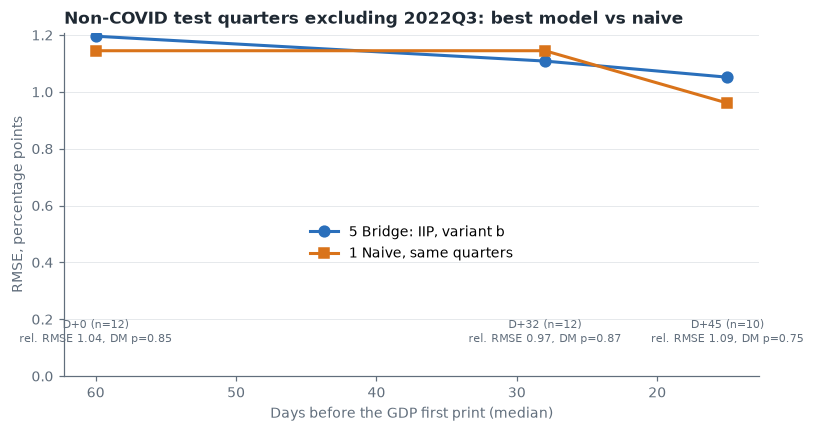

In [10]:
avg = main_x[main_x.model.isin(MAIN[1:])].groupby(["model", "variant"]).rel_rmse.mean().sort_values()
BEST_MODEL, BEST_VARIANT = avg.index[0]
print("Average non-COVID relative RMSE across dates:"); display(avg.round(3).to_frame())
print("Best:", BEST_MODEL, VARIANTS[BEST_VARIANT])
core_pick = main_x[(main_x.date == "D+32") & main_x.model.isin(["3 Bridge: core 8", "4 Bridge + AR: core 8"])].sort_values("rel_rmse").iloc[0]
CORE_MODEL, CORE_VARIANT = core_pick.model, core_pick.variant
print("Core 8 model used for the live call (lowest relative RMSE at D+32):", CORE_MODEL, VARIANTS[CORE_VARIANT])
best_rows = main_x[(main_x.variant == BEST_VARIANT) & main.model.isin([BEST_MODEL, "1 Naive"])]
display(best_rows.set_index(["date", "model"])[["n", "rmse", "rel_rmse", "dm_stat", "dm_p", "beats_naive_pct", "direction_hit_pct"]].round(2))

days_before = {}
for date in DATES:
    d = nowcasts[(nowcasts.variant == BEST_VARIANT) & (nowcasts.date == date) & (nowcasts.model == BEST_MODEL) & nowcasts.quarter.isin(WINDOW) & ~nowcasts.quarter.isin(COVID)]
    days_before[date] = d.days_before_gdp.median()

fig, ax = plt.subplots(figsize=(7.5, 4))
r_best = best_rows[best_rows.model == BEST_MODEL].set_index("date").loc[list(DATES)]
for model, color, marker in ((BEST_MODEL, BLUE, "o"), ("1 Naive", ORANGE, "s")):
    r = r_best if model == BEST_MODEL else r_best.assign(rmse=r_best.rmse / r_best.rel_rmse)  # naive on the same quarters
    xs = [days_before[d] for d in DATES]
    ax.plot(xs, r.rmse, color=color, marker=marker, ms=7, lw=2, label=f"{model}, variant {VARIANTS[BEST_VARIANT][1]}" if model != "1 Naive" else "1 Naive, same quarters")
    for x, (date, row) in zip(xs, r.iterrows()):
        if model != "1 Naive":
            ax.annotate(f"{date} (n={int(row.n)})\nrel. RMSE {row.rel_rmse:.2f}, DM p={row.dm_p:.2f}", (x, 0.12), ha="center", fontsize=7.5, color=MUTED)
ax.invert_xaxis(); ax.set_ylim(0, None); ax.grid(axis="y", color=GRID, lw=.6)
ax.set_xlabel("Days before the GDP first print (median)"); ax.set_ylabel("RMSE, percentage points")
ax.set_title("Non-COVID test quarters excluding 2022Q3: best model vs naive", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(.5, .3))
fig.tight_layout(); fig.savefig(REPORTS / "backtest_rmse_by_horizon.png", bbox_inches="tight", facecolor="white"); plt.show()

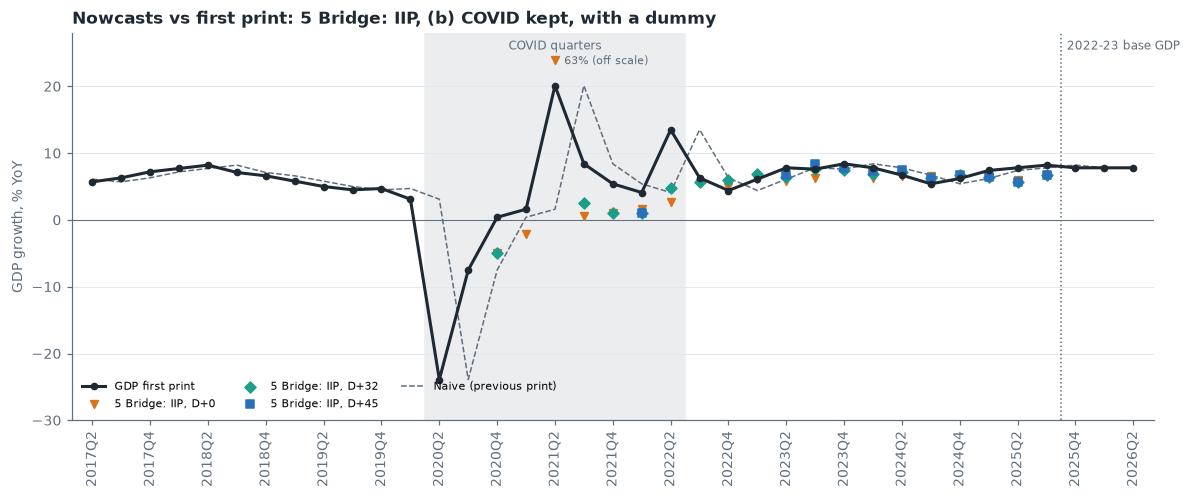

In [11]:
plot_q = [q for q in WINDOW + NEW_BASE if q in set(nowcasts.quarter)]
pos = {q: i for i, q in enumerate(WINDOW + NEW_BASE)}
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axvspan(pos["2020Q2"] - .5, pos["2022Q2"] + .5, color=COVID_BAND, zorder=0)
ax.text(pos["2021Q2"], 25.5, "COVID quarters", ha="center", color=MUTED, fontsize=8)
ax.axvline(pos["2025Q4"] - .5, color=MUTED, lw=1, ls=":")
ax.text(pos["2025Q4"] - .3, 25.5, "2022-23 base GDP", color=MUTED, fontsize=8)
act = GDP.reindex(WINDOW + NEW_BASE)
ax.plot([pos[q] for q in act.index], act.values, color=INK, lw=2, marker="o", ms=4, label="GDP first print", zorder=4)
for date, color, marker in zip(DATES, [ORANGE, TEAL, BLUE], ["v", "D", "s"]):
    d = nowcasts[(nowcasts.model == BEST_MODEL) & (nowcasts.variant == BEST_VARIANT) & (nowcasts.date == date)]
    ax.scatter([pos[q] for q in d.quarter], d.nowcast.clip(-28, 24), color=color, marker=marker, s=26, zorder=3, label=f"{BEST_MODEL}, {date}")
    for q, v in zip(d.quarter, d.nowcast):
        if not -28 <= v <= 24:
            ax.annotate(f"{v:.0f}% (off scale)", (pos[q], np.clip(v, -28, 24)), textcoords="offset points", xytext=(6, -3), fontsize=7.5, color=MUTED)
nv = nowcasts[(nowcasts.model == "1 Naive") & (nowcasts.variant == BEST_VARIANT) & (nowcasts.date == "D+0")]
ax.plot([pos[q] for q in nv.quarter], nv.nowcast, color=MUTED, lw=1, ls="--", label="Naive (previous print)", zorder=2)
ax.set_xticks(range(0, len(pos), 2), list(pos)[::2], rotation=90); ax.set_xlim(-.7, len(pos) - .3)
ax.axhline(0, color=MUTED, lw=.7); ax.grid(axis="y", color=GRID, lw=.6); ax.set_ylabel("GDP growth, % YoY"); ax.set_ylim(-30, 28)
ax.set_title(f"Nowcasts vs first print: {BEST_MODEL}, {VARIANTS[BEST_VARIANT]}", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=7.5, ncol=3, loc="lower left")
fig.tight_layout(); fig.savefig(REPORTS / "backtest_nowcast_vs_actual.png", bbox_inches="tight", facecolor="white"); plt.show()

## Sensitivity: without the unverified GDP quarters

2019Q3 and 2021Q3 are removed from both training and testing, and the main table is recomputed. 2021Q3 is a COVID quarter, and 2019Q3 comes before the first non-COVID test quarter, so this can change the headline table only through training.

In [12]:
nowcasts_unv = run_backtest(drop=UNVERIFIED, quarters=WINDOW)
main_unv = scorecard(nowcasts_unv, MAIN, covid=False, drop=UNVERIFIED, common=MAIN[:4])
main_unv.to_csv(PROCESSED / "backtest_metrics_main_without_unverified.csv", index=False)
cmp = main.merge(main_unv, on=["variant", "date", "model"], suffixes=("", "_without"))
display(cmp.set_index(["variant", "date", "model"])[["n", "n_without", "rmse", "rmse_without", "rel_rmse", "rel_rmse_without", "dm_p", "dm_p_without"]].round(2))
print("Largest RMSE change:", round((cmp.rmse - cmp.rmse_without).abs().max(), 3))

n  n_without  rmse  rmse_without  rel_rmse  rel_rmse_without  dm_p  dm_p_without
variant date model                                                                                                     
drop    D+0  1 Naive                11.0       10.0  1.05          0.96      1.00              1.00   NaN           NaN
             2 AR(1)                11.0       10.0  1.18          1.01      1.13              1.05  0.20          0.47
             3 Bridge: core 8       11.0       10.0  1.36          1.40      1.30              1.45  0.38          0.21
             4 Bridge + AR: core 8  11.0       10.0  1.60          1.17      1.52              1.22  0.22          0.31
             5 Bridge: IIP          11.0       10.0  1.20          1.16      1.14              1.21  0.58          0.39
        D+32 1 Naive                11.0       10.0  1.05          0.96      1.00              1.00   NaN           NaN
             2 AR(1)                11.0       10.0  1.18          1.01      1.13              1.05  0.20          0.47
             3 Bridge: core 8       11.0       10.0  1.26          1.32      1.20              1.38  0.58          0.36
             4 Bridge + AR: core 8  11.0       10.0  1.83          1.17      1.75              1.21  0.28          0.39
             5 Bridge: IIP          10.0        9.0  1.11          1.11      1.15              1.32  0.65          0.44
        D+45 1 Naive                11.0       10.0  1.05          0.96      1.00              1.00   NaN           NaN
             2 AR(1)                11.0       10.0  1.18          1.01      1.13              1.05  0.20          0.47
             3 Bridge: core 8       11.0       10.0  1.26          1.32      1.20              1.38  0.58          0.36
             4 Bridge + AR: core 8  11.0       10.0  1.83          1.17      1.75              1.21  0.28          0.39
             5 Bridge: IIP           6.0        6.0  1.26          1.26      1.34              1.34  0.54          0.54
dummy   D+0  1 Naive                13.0       13.0  2.28          2.28      1.00              1.00   NaN           NaN
             2 AR(1)                13.0       13.0  1.38          1.38      0.61              0.61  0.40          0.39
             3 Bridge: core 8       13.0       13.0  1.81          1.81      0.79              0.79  0.68          0.68
             4 Bridge + AR: core 8  13.0       13.0  1.79          1.80      0.79              0.79  0.67          0.67
             5 Bridge: IIP          13.0       13.0  1.17          1.09      0.51              0.48  0.37          0.35
        D+32 1 Naive                13.0       13.0  2.28          2.28      1.00              1.00   NaN           NaN
             2 AR(1)                13.0       13.0  1.38          1.38      0.61              0.61  0.40          0.39
             3 Bridge: core 8       13.0       13.0  2.11          2.05      0.93              0.90  0.86          0.82
             4 Bridge + AR: core 8  13.0       13.0  2.11          2.06      0.93              0.90  0.86          0.82
             5 Bridge: IIP          13.0       13.0  1.08          1.11      0.47              0.49  0.35          0.36
        D+45 1 Naive                13.0       13.0  2.28          2.28      1.00              1.00   NaN           NaN
             2 AR(1)                13.0       13.0  1.38          1.38      0.61              0.61  0.40          0.39
             3 Bridge: core 8       13.0       13.0  2.11          2.05      0.93              0.90  0.86          0.82
             4 Bridge + AR: core 8  13.0       13.0  2.11          2.06      0.93              0.90  0.86          0.82
             5 Bridge: IIP          10.0        9.0  1.05          1.05      1.09              1.25  0.75          0.52

Largest RMSE change: 0.666


## Live check: the three 2022-23 base quarters (illustration only, n = 3)

GDP from 2025Q4 is on the 2022-23 base, while every model is trained on 2011-12 base prints to 2025Q3. These scores are an illustration, not evidence. Two versions are shown:

- **Real time:** the data public on each nowcast date. Old-base core 8 first prints ran to May 2026, so 2026Q2 at D+32 and D+45 has only months 1 and 2.
- **Live method:** the method used for 2026Q3 below. It uses full-quarter 2022-23 base core 8 YoY from the OEA file dated 21 Oct 2026. **That file was published after these GDP prints**, so it checks the method, not a real-time record.

In [13]:
NEW_FILE_DATE = pd.Timestamp("2026-10-21")  # date in the OEA file name, Core_Industries_2022_23_20261021.xlsx
new = monthly[(monthly.indicator == "core8_overall_base2022") & (monthly.vintage == "latest") & monthly.value.notna()]
NEW_CORE = pd.Series(new.value.values, index=pd.PeriodIndex(new.ref_month, freq="M"))
assert new.source_url.str.endswith("Core_Industries_2022_23_20261021.xlsx").all()

def new_base_yoy(q):
    months = pd.PeriodIndex(quarter_months(q))
    return 100 * (NEW_CORE.loc[months].sum() / NEW_CORE.loc[months - 12].sum() - 1)

def live_method(model, variant, q, asof):
    """Fit on the whole old-base window with full quarters, then apply to 2022-23 base core 8 YoY."""
    feats = MODELS[model]
    if feats is None:
        return gdp_known(prevq(q), asof)
    rows = []
    for j in WINDOW:
        if variant == "drop" and (j in COVID or ("ar" in feats and prevq(j) in COVID)):
            continue
        r = [GDP[prevq(j)] if f == "ar" else yoy(f, j, (1, 2, 3), asof) for f in feats]
        if not np.isnan(r).any():
            rows.append((r, GDP[j], float(j in COVID)))
    X = np.column_stack([np.ones(len(rows)), np.array([r for r, _, _ in rows])])
    if variant == "dummy" and any(d for _, _, d in rows):
        X = np.column_stack([X, [d for _, _, d in rows]])
    beta = np.linalg.lstsq(X, np.array([y for _, y, _ in rows]), rcond=None)[0]
    x = [gdp_known(prevq(q), asof) if f == "ar" else new_base_yoy(q) for f in feats]
    return float(np.r_[1.0, x, [0.0] * (X.shape[1] - len(feats) - 1)] @ beta)

check = []
for q in NEW_BASE:
    asof = qend(q) + pd.Timedelta(days=32)
    for model in ["1 Naive", "3 Bridge: core 8", "4 Bridge + AR: core 8", "2 AR(1)"]:
        rt = nowcasts[(nowcasts.model == model) & (nowcasts.variant == CORE_VARIANT) & (nowcasts.date == "D+32") & (nowcasts.quarter == q)]
        lm = live_method(model, CORE_VARIANT, q, asof)
        check.append({"quarter": q, "model": model, "first_print": GDP[q], "core8_new_base_yoy": new_base_yoy(q),
                      "real_time_nowcast": rt.nowcast.iloc[0] if len(rt) else np.nan, "real_time_months": rt.months.iloc[0] if len(rt) else "",
                      "live_method_nowcast": lm})
check = pd.DataFrame(check)
check["real_time_error"] = check.real_time_nowcast - check.first_print
check["live_method_error"] = check.live_method_nowcast - check.first_print
print("Variant:", VARIANTS[CORE_VARIANT], "| nowcast date D+32")
display(check.round(2))
display(check.groupby("model")[["real_time_error", "live_method_error"]].apply(lambda e: np.sqrt((e ** 2).mean())).rename(columns=lambda c: c.replace("error", "rmse")).round(2))

Variant: (a) COVID dropped from training | nowcast date D+32


,quarter,model,first_print,core8_new_base_yoy,real_time_nowcast,real_time_months,live_method_nowcast,real_time_error,live_method_error
0,2025Q4,1 Naive,7.8,3.33,8.20,,8.20,0.40,0.40
1,2025Q4,3 Bridge: core 8,7.8,3.33,5.74,core8:12,6.08,-2.06,-1.72
2,2025Q4,4 Bridge + AR: core 8,7.8,3.33,7.28,core8:12,7.24,-0.52,-0.56
3,2025Q4,2 AR(1),7.8,3.33,7.93,,7.93,0.13,0.13
4,2026Q1,1 Naive,7.8,3.75,7.80,,7.80,0.00,0.00
5,2026Q1,3 Bridge: core 8,7.8,3.75,5.79,core8:123,6.21,-2.01,-1.59
6,2026Q1,4 Bridge + AR: core 8,7.8,3.75,6.83,core8:123,7.06,-0.97,-0.74
7,2026Q1,2 AR(1),7.8,3.75,7.58,,7.58,-0.22,-0.22
8,2026Q2,1 Naive,7.8,3.94,7.80,,7.80,0.00,0.00
9,2026Q2,3 Bridge: core 8,7.8,3.94,5.64,core8:12,6.28,-2.16,-1.52


,real_time_rmse,live_method_rmse
model,,
1 Naive,0.23,0.23
2 AR(1),0.19,0.19
3 Bridge: core 8,2.07,1.61
4 Bridge + AR: core 8,0.80,0.67


## Live call: 2026Q3

**The model and the data are on different bases.** The models are fitted on 2011-12 base GDP and core 8. Both series have since moved to the 2022-23 base, and the old-base core 8 stops at May 2026. The new core 8 also adds iron ore as a ninth sector. The old-base coefficients are applied to new-base core 8 YoY as if they were comparable, which hasn't been tested beyond the 3 quarters above.

The range is ±1 non-COVID backtest RMSE at D+32, excluding 2022Q3. **It ignores the base mismatch, so it is too narrow.**

In [14]:
TODAY = pd.Timestamp(dt.date.today())
LIVE_Q = "2026Q3"
asof = TODAY
months = pd.PeriodIndex(quarter_months(LIVE_Q))
assert NEW_FILE_DATE <= TODAY and months.isin(NEW_CORE.index).all()
live_yoy = new_base_yoy(LIVE_Q)
first_rows = monthly[(monthly.indicator == "core8_overall_base2022") & (monthly.vintage == "first") & monthly.ref_month.isin(months.astype(str)) & monthly.value.notna()]
alt_cur = [first_rows.set_index("ref_month").value.get(str(m), NEW_CORE[m]) for m in months]
alt_yoy = 100 * (sum(alt_cur) / NEW_CORE.loc[months - 12].sum() - 1)
prev_print = GDP[prevq(LIVE_Q)]
assert REL[prevq(LIVE_Q)] < asof

card32 = main_x[(main_x.date == "D+32") & (main_x.variant == CORE_VARIANT)].set_index("model")
live = []
for model in ["1 Naive", "2 AR(1)", "3 Bridge: core 8", "4 Bridge + AR: core 8"]:
    point = live_method(model, CORE_VARIANT, LIVE_Q, asof)
    r = card32.loc[model, "rmse"]
    live.append({"model": model, "point": point, "rmse_d32": r, "rel_rmse_d32": card32.loc[model, "rel_rmse"], "dm_p": card32.loc[model, "dm_p"], "low": point - r, "high": point + r})
live = pd.DataFrame(live)
display(live.round(2))
print(f"Core 8 (2022-23 base) YoY for {LIVE_Q}: {live_yoy:.2f}% from the 21 Oct 2026 file; {alt_yoy:.2f}% using the Jul and Aug first prints instead")

head = live[live.model == CORE_MODEL].iloc[0]
naive = live[live.model == "1 Naive"].iloc[0]
LIVE_PATH = REPORTS / "live_nowcast_2026Q3.md"
FREEZE = pd.Timestamp("2026-11-30")
text = f"""# Live nowcast: India real GDP growth, {LIVE_Q} (Jul to Sep 2026)

Made on {TODAY:%d %b %Y}, by notebooks/04_models.ipynb. It is not edited after 30 Nov 2026, when the first print is due.

## Nowcast

**{head.low:.1f}% to {head.high:.1f}% YoY** ({CORE_MODEL}, {VARIANTS[CORE_VARIANT]}, centre {head.point:.1f}%).

**In the backtest, no model beat the naive rule outside COVID.** The naive rule's {naive.point:.1f}% is as defensible a central guess as the model's. The core 8 bridges also nowcast too low in all three 2022-23 base quarters so far (see the notebook).

| Model | Centre | Range (±1 RMSE) | Backtest RMSE vs naive |
|---|---|---|---|
""" + "".join(f"| {r.model} | {r.point:.1f}% | {r.low:.1f}% to {r.high:.1f}% | {r.rel_rmse_d32:.2f} |\n" for r in live.itertuples()) + f"""
The range is ±1 RMSE from the non-COVID real-time backtest at D+32, excluding 2022Q3 (2011-12 base). **It ignores the base mismatch below, so it understates the uncertainty.**

## Base mismatch

The models were fitted on 2011-12 base GDP first prints and 2011-12 base core 8, to 2025Q3. GDP is now published on the 2022-23 base (from 2025Q4), and core 8 has moved to the 2022-23 base, which adds iron ore as a ninth sector. The old-base coefficients are applied to new-base core 8 YoY as though the two were comparable. Only 3 new-base quarters exist to check this, which is too few to measure it.

## Data used

| Input | Value | Source | Public by |
|---|---|---|---|
| Core 8 YoY, Jul to Sep 2026 vs Jul to Sep 2025 (2022-23 base) | {live_yoy:.2f}% | {new.source_url.iloc[0]} | 21 Oct 2026 (date in file name) |
| Same, using the Jul and Aug 2026 first prints from the monthly press releases | {alt_yoy:.2f}% | eaindustry.nic.in press releases | 21 Sep 2026 |
| Previous quarter's GDP first print, {prevq(LIVE_Q)} (2022-23 base) | {prev_print:.1f}% | {gdp_table.loc[prevq(LIVE_Q), 'source_url']} | {REL[prevq(LIVE_Q)]:%d %b %Y} |

The Jul to Sep 2025 values in the YoY are from the 2022-23 back series in the same file. They were never published as first prints, unlike the training data.

## Backtest context

At D+32, outside COVID and excluding 2022Q3, {CORE_MODEL} had RMSE {head.rmse_d32:.2f} points, against {naive.rmse_d32:.2f} for the naive rule (relative RMSE {head.rel_rmse_d32:.2f}, Diebold-Mariano p = {head.dm_p:.2f}, n = {int(card32.loc[CORE_MODEL, 'n'])} test quarters). With so few quarters, the test can't tell the two apart. See notebooks/04_models.ipynb.
"""
if TODAY <= FREEZE and not LIVE_PATH.exists():
    LIVE_PATH.write_text(text, encoding="utf8")
    print("Wrote", LIVE_PATH)
else:
    print("The live nowcast file already exists and is never rewritten. Later additions are appended below.")
def live_change(variant, q, asof):
    rows = []
    for j in WINDOW:
        if variant == "drop" and (j in COVID or prevq(j) in COVID):
            continue
        x = yoy("core8", j, (1, 2, 3), asof) - yoy("core8", prevq(j), (1, 2, 3), asof)
        if not np.isnan(x):
            rows.append((x, GDP[j] - GDP[prevq(j)], float(j in COVID)))
    X = np.column_stack([np.ones(len(rows)), [r[0] for r in rows]])
    if variant == "dummy" and any(r[2] for r in rows):
        X = np.column_stack([X, [r[2] for r in rows]])
    beta = np.linalg.lstsq(X, np.array([r[1] for r in rows]), rcond=None)[0]
    dx = new_base_yoy(q) - new_base_yoy(prevq(q))
    return gdp_known(prevq(q), asof) + float(np.r_[1.0, dx, [0.0] * (X.shape[1] - 2)] @ beta)

m8 = main_x[(main_x.model == M8) & (main_x.variant == CORE_VARIANT) & (main_x.date == "D+32")].iloc[0]
m8_point = live_change(CORE_VARIANT, LIVE_Q, asof)
m8_line = (f"**Model 8 (change model, Phase 4b), added {TODAY:%d %b %Y}:** {m8_point:.1f}% (range {m8_point - m8.rmse:.1f}% to {m8_point + m8.rmse:.1f}%, ±1 RMSE {m8.rmse:.2f}, "
           f"{VARIANTS[CORE_VARIANT]}, D+32, excluding 2022Q3; relative RMSE {m8.rel_rmse:.2f} vs naive, DM p = {m8.dm_p:.2f}, n = {int(m8.n)}). "
           f"It adds the predicted change to the {prevq(LIVE_Q)} first print of {prev_print:.1f}%. The predicted change comes from the move in 2022-23 base core 8 YoY "
           f"from {new_base_yoy(prevq(LIVE_Q)):.2f}% in {prevq(LIVE_Q)} to {live_yoy:.2f}% in {LIVE_Q}, both from the 21 Oct 2026 file. The same base mismatch applies.")
current = LIVE_PATH.read_text(encoding="utf8")
if TODAY <= FREEZE and "**Model 8" not in current:
    with LIVE_PATH.open("a", encoding="utf8") as f:
        f.write(("" if current.endswith("\n") else "\n") + "\n" + m8_line + "\n")
    print("Appended the model 8 line")
print(LIVE_PATH.read_text(encoding="utf8"))

,model,point,rmse_d32,rel_rmse_d32,dm_p,low,high
0,1 Naive,7.80,1.05,1.00,NaN,6.75,8.85
1,2 AR(1),7.58,1.18,1.13,0.20,6.40,8.76
2,3 Bridge: core 8,7.04,1.26,1.20,0.58,5.78,8.29
3,4 Bridge + AR: core 8,7.50,1.83,1.75,0.28,5.67,9.33


Core 8 (2022-23 base) YoY for 2026Q3: 6.27% from the 21 Oct 2026 file; 6.03% using the Jul and Aug first prints instead
The live nowcast file already exists and is never rewritten. Later additions are appended below.
# Live nowcast: India real GDP growth, 2026Q3 (Jul to Sep 2026)

Made on 03 Nov 2026, by notebooks/04_models.ipynb. It is not edited after 30 Nov 2026, when the first print is due.

## Nowcast

**5.8% to 8.3% YoY** (3 Bridge: core 8, (a) COVID dropped from training, centre 7.0%).

**In the backtest, no model beat the naive rule outside COVID.** The naive rule's 7.8% is as defensible a central guess as the model's. The core 8 bridges also nowcast too low in all three 2022-23 base quarters so far (see the notebook).

| Model | Centre | Range (±1 RMSE) | Backtest RMSE vs naive |
|---|---|---|---|
| 1 Naive | 7.8% | 6.8% to 8.8% | 1.00 |
| 2 AR(1) | 7.6% | 6.4% to 8.8% | 1.13 |
| 3 Bridge: core 8 | 7.0% | 5.8% to 8.3% | 1.20 |
| 4 Bridge + AR: core 8 | 7.5% | 5.7% to 9.3% | 1.

## Numbers behind the findings

In [15]:
for variant in VARIANTS:
    t = main[main.variant == variant].pivot(index="model", columns="date", values=["rmse", "rel_rmse", "dm_p"]).round(2)
    print(VARIANTS[variant]); print(t.to_string())
print(addons[(addons["sample"] == "non-COVID") & (addons.model != "1 Naive")][["test", "variant", "date", "model", "n", "rmse", "rel_rmse"]].round(2).to_string(index=False))
for variant in VARIANTS:
    print("Without 2022Q3,", VARIANTS[variant]); print(main_x[main_x.variant == variant].pivot(index="model", columns="date", values=["n", "rmse", "rel_rmse", "dm_p"]).round(2).to_string())
print(covid_card[covid_card.date == "D+32"][["variant", "model", "n", "rmse", "rel_rmse"]].round(2).to_string(index=False))
print(cmp[["variant", "date", "model", "rel_rmse", "rel_rmse_without"]].assign(change=lambda d: d.rel_rmse_without - d.rel_rmse).round(2).sort_values("change").to_string(index=False))
print(main_x[main_x.model.isin(["1 Naive", M8])][["variant", "date", "model", "n", "rmse", "bias", "rel_rmse", "dm_p", "beats_naive_pct", "direction_hit_pct"]].round(2).to_string(index=False))
print(main[main.model == M8][["variant", "date", "n", "rmse", "rel_rmse", "dm_p"]].round(2).to_string(index=False))
print(covid_card[covid_card.model.isin(["1 Naive", M8])][["variant", "date", "model", "n", "rmse", "rel_rmse"]].round(2).to_string(index=False))

(a) COVID dropped from training
                       rmse             rel_rmse              dm_p            
date                    D+0  D+32  D+45      D+0  D+32  D+45   D+0  D+32  D+45
model                                                                         
1 Naive                1.05  1.05  1.05     1.00  1.00  1.00   NaN   NaN   NaN
2 AR(1)                1.18  1.18  1.18     1.13  1.13  1.13  0.20  0.20  0.20
3 Bridge: core 8       1.36  1.26  1.26     1.30  1.20  1.20  0.38  0.58  0.58
4 Bridge + AR: core 8  1.60  1.83  1.83     1.52  1.75  1.75  0.22  0.28  0.28
5 Bridge: IIP          1.20  1.11  1.26     1.14  1.15  1.34  0.58  0.65  0.54
8 Change: Δ core 8     1.13  1.09  1.09     1.17  1.17  1.17  0.15  0.30  0.30
(b) COVID kept, with a dummy
                       rmse             rel_rmse              dm_p            
date                    D+0  D+32  D+45      D+0  D+32  D+45   D+0  D+32  D+45
model                                                                 

## Findings

RMSE is in percentage points of GDP growth. Relative RMSE below 1 means the model beat the naive rule on the same quarters.

**Short answer: outside COVID, nothing reliably beats repeating last quarter's first print, at any nowcast date.**

1. **With COVID dropped from training (variant a), every model is worse than naive.** On the 11 test quarters (2023Q1 to 2025Q3), naive has RMSE 1.05. The core 8 bridge has 1.36 at D+0 and 1.26 at D+32 and D+45 (relative 1.30 and 1.20), AR(1) has 1.18, bridge + AR has 1.60 to 1.83, and the IIP bridge has 1.11 to 1.26.
2. **Variant (b)'s apparent wins come from one quarter.** With 2022Q3 included, AR(1) scores 0.61 and the IIP bridge 0.47 to 0.51. In 2022Q3, naive carries forward 2022Q2's 13.5% base-effect print against an actual 6.3%. Without that quarter (n = 12), AR(1) is at 1.12, the core 8 bridge at 1.64 to 1.81, and the IIP bridge at 1.04, 0.97 and 1.09 at the three dates.
3. **The best case is the IIP bridge at D+32 (variant b, excluding 2022Q3): relative RMSE 0.97, Diebold-Mariano p = 0.87.** It beats naive in 67% of quarters and calls the direction of change in 75%. A 3% RMSE gain on 12 quarters is indistinguishable from zero.
4. **More data within the quarter helps a little, but not enough.** The core 8 bridge improves from 1.36 at D+0 to 1.26 at D+32 once month 3 arrives, but stays above naive's 1.05. IIP improves from 1.20 to 1.11. D+45 adds nothing for core 8, which is already complete at D+32.
5. **The core 8 bridge is biased low.** Its mean error is -0.85 to -1.01 points in variant (a). On the three 2022-23 base quarters it under-predicted by 2.0 to 2.2 points each time in real time. Core 8 growth has run well below GDP growth since 2023, so the 2018 to 2020 relationship doesn't hold.
6. **Indicators earn their keep only when growth moves sharply.** On 8 COVID test quarters (variant b, D+32), the core 8 bridge has RMSE 4.29 against naive's 10.67 (relative 0.40). AR(1) does worse than naive there (21.41), because it extrapolates the last swing.
7. **No add-on or look-ahead series fixes this.** Exports cut the bridge's RMSE from 1.44 to 1.33 (variant a, D+32, n = 6), but naive has 0.94 on those quarters. GST can be tested only in variant (b), on 5 quarters, where it is worse than the bridge (3.10 against 2.54). E-way bills `[look-ahead]` make the bridge worse (1.49 against 1.37, n = 8). Diesel `[look-ahead]` helps slightly (1.48 against 1.58, n = 5) but stays above naive's 0.90, despite using latest-vintage data.
8. **Confidence is low throughout.** Every non-COVID comparison rests on 5 to 13 test quarters, and no Diebold-Mariano p-value is below 0.10. Removing the unverified GDP quarters shrinks training and moves some relative RMSEs by up to 0.53 (bridge + AR, variant a), but leaves no model below naive in variant (a). The live check on the three 2022-23 base quarters (n = 3, illustration only) agrees: naive has RMSE 0.23 and AR(1) 0.19, against 2.07 for the core 8 bridge.

**Live call for 2026Q3 (made 3 Nov 2026):** the core 8 bridge gives 7.0%, with a ±1 RMSE range of 5.8% to 8.3%. Naive gives 7.8%. Given findings 1, 5 and the base mismatch, the naive 7.8% is at least as credible as the model's 7.0%, and the bridge's record of under-predicting suggests its centre is too low. See `reports/live_nowcast_2026Q3.md`.

**What this means:** quarterly Indian GDP first prints have been very smooth since 2023, varying between 5.4% and 8.4% from 2023Q1 to 2025Q3 and close to the previous print. That makes naive hard to beat. The monthly indicators here track the big swings, not the small ones. A better model needs either a target-relative signal that holds up (for example, the gap between core 8 and GDP growth) or more test quarters, and the 2022-23 base resets the sample.

### Phase 4b: model 8 (change model, pre-registered)

**Model 8 doesn't beat naive outside COVID either.** On the main quarter sets without 2022Q3, it has relative RMSE 1.17 in variant (a) at every date (RMSE 1.13 at D+0 and 1.09 at D+32 and D+45, DM p = 0.15 to 0.30). In variant (b) it has 1.71 at D+0 and 1.61 at D+32 and D+45 (DM p = 0.10 to 0.19).

- **Coverage:** in variant (a) it has 9 or 10 of the 11 quarters. 2023Q1 has fewer than 8 training quarters, and at D+32 and D+45 2025Q1 is missing, because the Dec 2024 core 8 first print is blank and the change needs the previous quarter's YoY on the same months.
- **Bias:** anchoring on the previous print removes most of the bridge's bias, which falls from -0.85 to -0.40 at D+32 in variant (a).
- **Like for like:** at D+32 in variant (a), model 8's relative RMSE is 1.17 and the core 8 bridge's is 1.20, each against naive on its own quarters. Both are worse than naive. Their raw RMSEs (1.09 on 9 quarters, 1.26 on 11) cover different quarters and can't be compared directly.
- **With 2022Q3,** variant (b) gives 0.75 to 0.82, driven by the same quarter as before.
- **COVID quarters:** 0.42 to 0.47 relative to naive.

**Live line, appended to the live file on 3 Nov 2026:** 7.7% (6.6% to 8.8%), from the 2026Q2 print of 7.8% and a 2.3-point rise in new-base core 8 YoY.
